# 01. Данные, дубликаты и кадры

Вход: MP4, visible-аннотации, splits. Выход: проверенные video-level splits, manifest, архивы кадров.

папка`notebooks_colab_full`
в `MyDrive/ML6/`.
Вычисления читают локальные кадры; результаты нового запуска пишутся в `runs/RUN_ID/`.
train-MP4 удаляются после проверки архивов всех аннотированных чистых кадров.

In [ ]:
import sys, os, subprocess, importlib.util
from pathlib import Path
IN_COLAB = 'google.colab' in sys.modules or Path('/content').is_dir()
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT = Path('/content/drive/MyDrive/ML6')
else:
    PROJECT = Path('D:/ML6')
RUN_ID = 'blue_aug_20261112_v2'  # одинаковый во всех 10 ноутбуках; старый run не меняем
BUNDLE = PROJECT / 'notebooks_colab_full'
assert (BUNDLE / 'tracking_lab.py').is_file(), BUNDLE
packages = {'scipy':'scipy', 'pandas':'pandas', 'cv2':'opencv-python-headless',
    'matplotlib':'matplotlib', 'tqdm':'tqdm', 'trackeval':'trackeval==1.3.0',
    'cryptography':'cryptography', 'imageio':'imageio', 'imageio_ffmpeg':'imageio-ffmpeg'}
missing = [p for m,p in packages.items() if importlib.util.find_spec(m) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
# Совместимую пару torch/torchvision предоставляет Colab; автоматически её не заменяем.
sys.path.insert(0, str(BUNDLE))
import tracking_lab as tl
assert Path(tl.__file__).resolve() == (BUNDLE / 'tracking_lab.py').resolve(), 'Перезапустите runtime: загружен старый модуль'
assert tl.SCHEMA == 4, 'Перезапустите runtime после обновления исходного кода'
import torch, pandas as pd, numpy as np, matplotlib.pyplot as plt
from IPython.display import display, Video, HTML, Image
lab = tl.Lab(PROJECT, RUN_ID)
torch.hub.set_dir(str(PROJECT / 'pretrained_cache'))
display(pd.Series(lab.environment(), name='Среда'))
print('Запуск:', RUN_ID, '| Результаты:', lab.root)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


,Среда
python,"3.13.16 (main, Oct 1 2026, 15:40:24) [GCC 13...."
packages,"{'torch': '2.14.1+cu130', 'torchvision': '0.29..."
device,cuda
gpu,NVIDIA A100-SXM4-80GB


Запуск: blue_aug_20261112_v2 | Результаты: /content/drive/MyDrive/ML6/runs/blue_aug_20261112_v2


Исходный локальный аудит до очистки: 172 видео / 11,0003 GiB; 107 train / 65 test.
`uid_vid_00220.mp4` содержит повтор ID в одном кадре и исключается. Контроль
декодирования проверил первые/последние и 5 аннотированных позиций; это не проверка
каждого кадра MP4. Ни точных дубликатов, ни кандидатов по dHash не найдено.
После 00 остаётся 151 MP4: train 94, val 12, dev 5, final 20, reserve 20.
Аудит ниже повторяется для фактических файлов Drive. `trim_dataset.py` не вызывается.
Если MP4 уже удалены после готовых архивов, повторный запуск восстанавливается из
manifest/архивов и проверяет сохранённые аннотации вместо повторного открытия видео.

In [ ]:
SOURCE=PROJECT/'tracking-dataset-main/dataset/personpath22'
PREPARED=tl.lifecycle.prepared_data_available(lab)
if PREPARED:
    display(pd.Series(tl.lifecycle.audit_prepared_sources(lab,SOURCE)))
    table=pd.read_csv(lab.path('data/manifests/inventory.csv'))
else:
    assert lab.path('data/manifests/active_splits_after_pruning.json').exists(), 'Сначала выполните очистку в 00'
    if IN_COLAB:
        DATASET=tl.stage_dataset(SOURCE,'/content/personpath22_aug_v2',
            reconnect=lambda: drive.mount('/content/drive',force_remount=True))
    else:
        DATASET=SOURCE
    table=tl.inventory(lab,DATASET)
display(table.groupby(['original_split','valid'], dropna=False).size().rename('Видео').to_frame())
display(table.loc[~table.valid, ['video','problems']])
display(pd.DataFrame(tl.load_json(lab.path('data/manifests/duplicate_edges.json'))))

,0
prepared,True
frames,16047
retired_train_mp4,94
recovery,Use verified clean JPEG archives; do not recon...


,,Видео
original_split,valid,
test,True,45
train,True,106


,video,problems


""


Точные и потенциальные визуальные дубликаты объединяются до разбиения.
Группа, пересекающая source train/test, целиком карантинируется. Train и val
используют source train; final — source test с исключением пяти старых видео.
Остальные test-видео остаются резервом
отсутствия всех перекодированных копий. Для ReID ключ: `(video_id, track_id)`.

In [ ]:
splits=tl.load_json(lab.path('data/manifests/splits.json')) if PREPARED else tl.make_splits(lab,table)
display(pd.DataFrame([{'Набор':s,'Видео':len(v)} for s,v in splits.items()]))
display(pd.Series(tl.load_json(lab.path('data/manifests/exposure_ledger.json'))))
LOCAL = '/content/ml6_full_frames' if IN_COLAB else str(lab.path('local_frames'))
if PREPARED:
    tl.cache_frames(lab,LOCAL,splits=('train','val','dev','final'))
    summary=tl.frame_summary(tl.load_json(lab.path('data/manifests/frames.json')))
else:
    summary=tl.prepare_frames(lab,table,splits,LOCAL)
display(summary.groupby('split')[['frames','seconds','people','small']].sum().rename(
    columns={'frames':'Кадры','seconds':'Секунды','people':'Рамки людей','small':'Малые рамки'}))

,Набор,Видео
0,train,94
1,val,12
2,dev,5
3,final,20
4,quarantine,0
5,reserve,20


,0
known_exposed,"[uid_vid_00008.mp4, uid_vid_00009.mp4, uid_vid..."
assumption,User accepted new held-out videos as independe...
source,Pinned split before requested cleanup; no resh...


Локальный кэш:   0%|          | 0/131 [00:00<?, ?архив/s]

Архив → /content:   0%|          | 0.00/26.1M [00:00<?, ?B/s]

Архив → /content:   0%|          | 0.00/27.2M [00:00<?, ?B/s]

Архив → /content:   0%|          | 0.00/304M [00:00<?, ?B/s]

... (125 outputs left out)

Архив → /content:   0%|          | 0.00/9.88M [00:00<?, ?B/s]

Архив → /content:   0%|          | 0.00/154M [00:00<?, ?B/s]

Архив → /content:   0%|          | 0.00/29.2M [00:00<?, ?B/s]

,Кадры,Секунды,Рамки людей,Малые рамки
split,,,,
dev,561,110.888417,15009,3323
final,2320,459.646133,50947,19166
train,12031,2386.022517,260103,75804
val,1135,223.966908,20686,7256


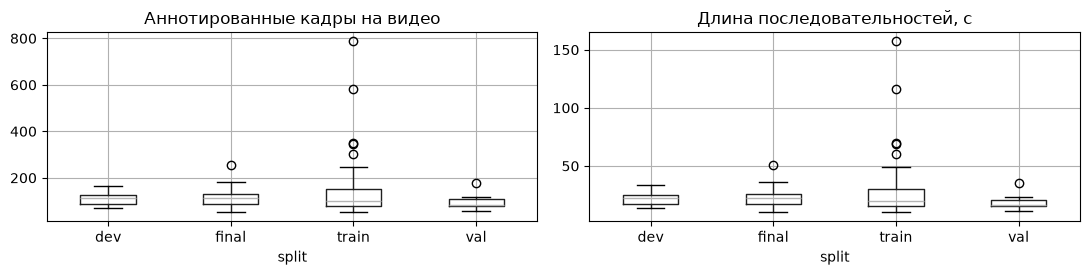

In [ ]:
fig, axes = plt.subplots(1,2,figsize=(11,3))
summary.boxplot(column='frames',by='split',ax=axes[0]); axes[0].set_title('Аннотированные кадры на видео')
summary.boxplot(column='seconds',by='split',ax=axes[1]); axes[1].set_title('Длина последовательностей, с')
plt.suptitle(''); plt.tight_layout(); plt.show()

исходное изображение, изменённое и рамки с исходными ID.
Геометрия и все per-instance поля фильтруются совместно. Для перекрытий требуется
не менее 65% видимой площади каждой рамки; иначе воздействие отклоняется.

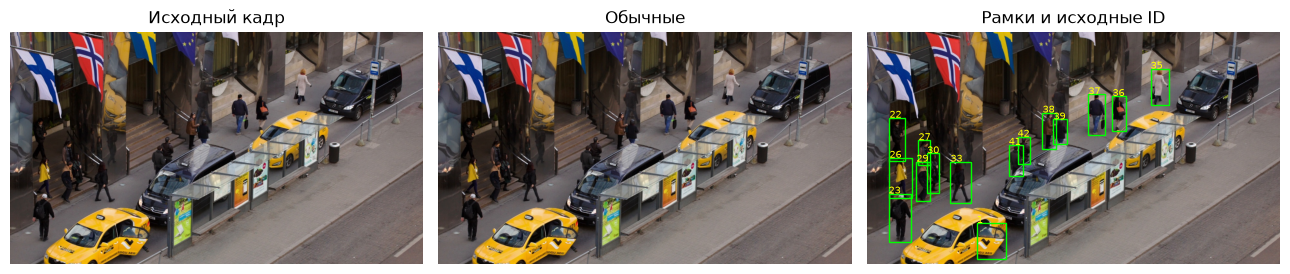

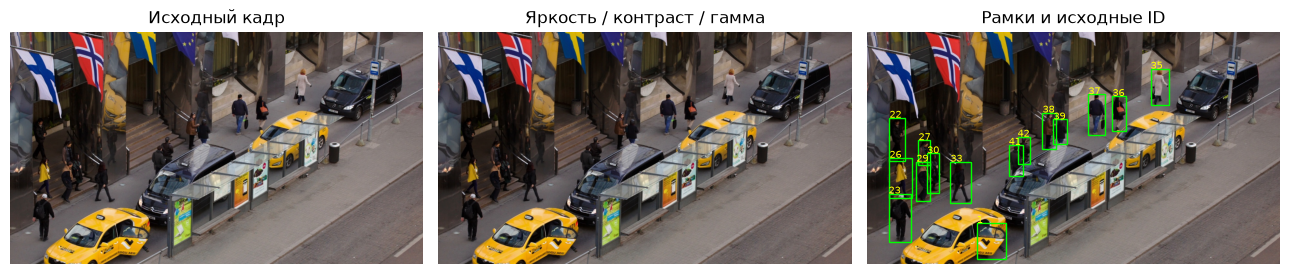

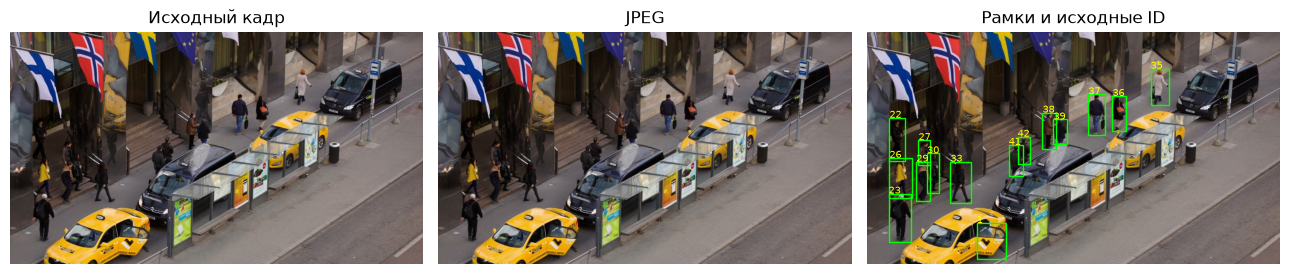

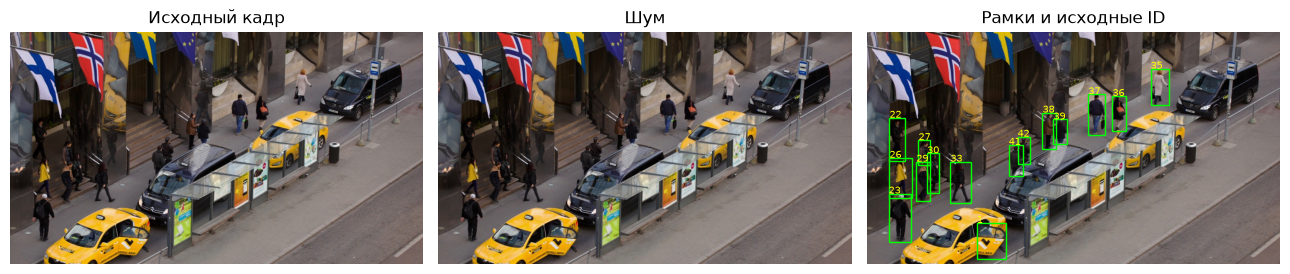

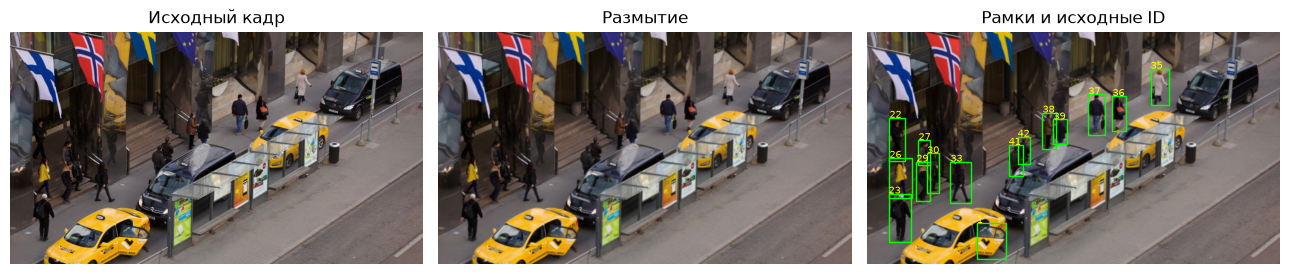

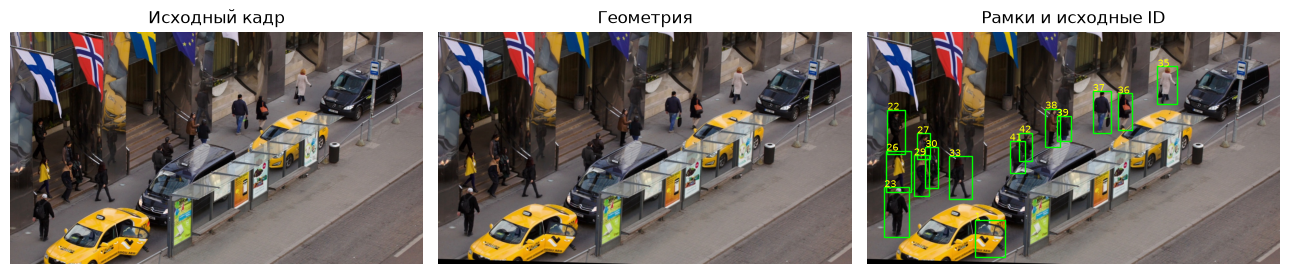

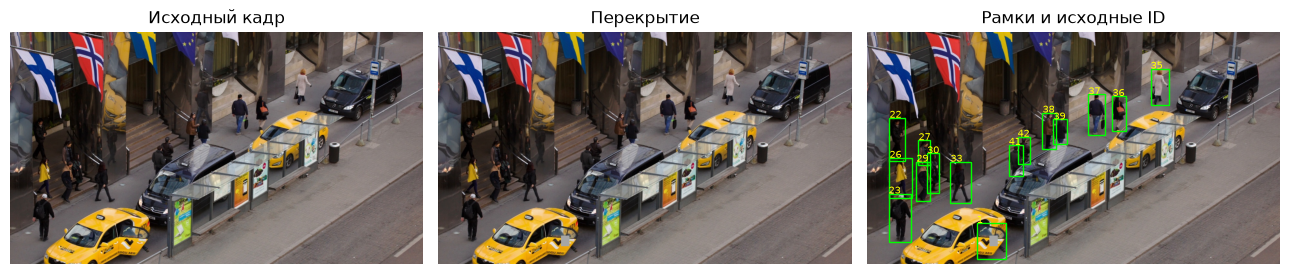

,Видео,Кадр,Воздействие,Применено,Людей_до,Людей_после,Удалённые_ID,Linf,Пример
0,uid_vid_00000.mp4,0,Обычные,False,15,15,[],0.000000,/content/drive/MyDrive/ML6/runs/blue_aug_20261...
1,uid_vid_00000.mp4,0,Яркость / контраст / гамма,True,15,15,[],0.027577,/content/drive/MyDrive/ML6/runs/blue_aug_20261...
2,uid_vid_00000.mp4,0,JPEG,True,15,15,[],0.211765,/content/drive/MyDrive/ML6/runs/blue_aug_20261...
3,uid_vid_00000.mp4,0,Шум,True,15,15,[],0.047422,/content/drive/MyDrive/ML6/runs/blue_aug_20261...
4,uid_vid_00000.mp4,0,Размытие,True,15,15,[],0.413096,/content/drive/MyDrive/ML6/runs/blue_aug_20261...
5,uid_vid_00000.mp4,0,Геометрия,True,15,15,[],1.000000,/content/drive/MyDrive/ML6/runs/blue_aug_20261...
6,uid_vid_00000.mp4,0,Перекрытие,True,15,15,[],0.654131,/content/drive/MyDrive/ML6/runs/blue_aug_20261...


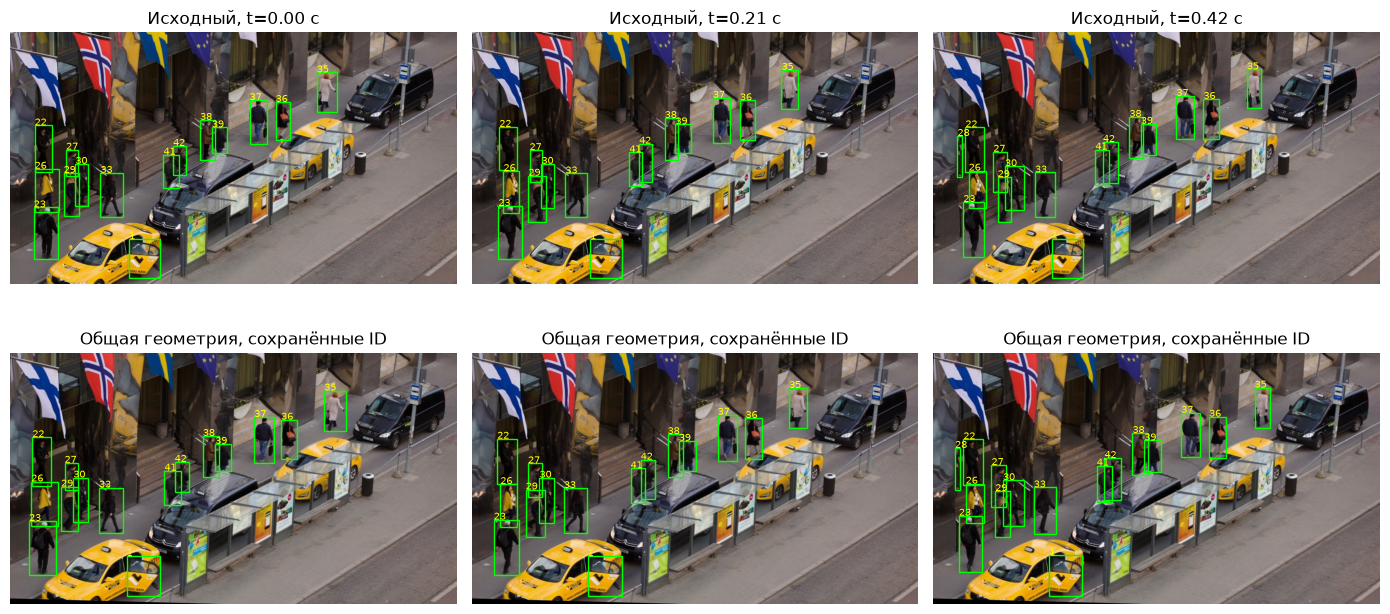

,Кадр,Время,ID_до,ID_после
0,0,0.000000,"[1, 22, 23, 26, 27, 29, 30, 33, 35, 36, 37, 38...","[1, 22, 23, 26, 27, 29, 30, 33, 35, 36, 37, 38..."
1,5,0.208542,"[1, 22, 23, 26, 27, 29, 30, 33, 35, 36, 37, 38...","[1, 22, 23, 26, 27, 29, 30, 33, 35, 36, 37, 38..."
2,10,0.417083,"[1, 22, 23, 26, 27, 28, 29, 30, 33, 35, 36, 37...","[1, 22, 23, 26, 27, 28, 29, 30, 33, 35, 36, 37..."


In [ ]:
display(tl.preview_augmentations(lab,samples=1))
display(tl.preview_temporal_augmentation(lab))

 удаляем именно исходные train-MP4.
Проверка требует **всех аннотированных позиций**, полного состава ZIP, SHA256
архива и каждого JPEG, успешного декодирования и совпадения размеров. При любом
несовпадении удаление не начинается. Сохраняются чистые JPEG95 после стандартизации
размера, аннотации, manifests и журналы. Неаннотированные кадры и аудио в JPEG-архив
не входят. После удаления обучение и preview читают архивы, а не исходные MP4.

In [ ]:
assert lab.cfg['train_frames_per_video'] is None, 'До удаления MP4 сохраните все аннотированные кадры'
if lab.cfg['retire_train_mp4']:
    retirement=tl.lifecycle.retire_train_mp4(lab,SOURCE)
    print('Train-MP4 удалены:',retirement['complete'],'| видео:',len(retirement['entries']))
    print('Осталось MP4 на Drive:',len(list((SOURCE/'raw_data').glob('*.mp4'))))
else:
    display(pd.Series(tl.lifecycle.verify_clean_archives(lab,SOURCE)))

Проверка чистых архивов train:   0%|          | 0/94 [00:00<?, ?видео/s]

SHA256 до удаления:   0%|          | 0/94 [00:00<?, ?файл/s]

Удаление по проверенному списку:   0%|          | 0/94 [00:00<?, ?файл/s]

Train-MP4 удалены: True | видео: 94
Осталось MP4 на Drive: 57


Кадры извлекаются последовательным декодированием
Каждый выбранный кадр должен декодироваться. Train использует все аннотированные кадры;
val/dev/final сохраняют полную аннотированную сетку и реальные timestamp/FPS.
Полностью пустые позиции без записей в аннотациях не выдумываются. Протокол visible
keyframes локальный и не является официальным PersonPath22 leaderboard.